# 4. Experimentos 2 e 3 – Desbalanceamento e otimização de hiperparâmetros

**Projeto:** Detecção de fraudes em transações financeiras com aprendizado supervisionado  
**Disciplina:** Inteligência Artificial – 7º semestre – Ciência da Computação  
**Instituição:** Universidade Presbiteriana Mackenzie – Faculdade de Computação e Informática  
**Professor:** Prof. Dr. Ivan Carlos Alcântara de Oliveira

| Integrante | RA | E-mail |
|---|---|---|
| Cheuk Ki Yu | 10419664 | cheuk.yu@mackenzista.com.br |
| Gabriela Nellessen de Sousa | 10441930 | [e-mail a preencher] |
| Milton Almeida Leoncio | 10416764 | milton.almeida@live.com |

**Síntese:** Compara ponderação de classes, subamostragem e SMOTE; otimiza XGBoost, LightGBM e MLP com Optuna e escolhe o modelo final de cada base pela AUPRC na validação.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-11-20 | Milton Almeida Leoncio | Versão final do projeto (N2) |

In [1]:
# ========================================================================================
# Projeto: Detecção de fraudes em transações financeiras com aprendizado supervisionado
# Disciplina: Inteligência Artificial - 7º semestre - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática (FCI)
# Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrantes:
#   Cheuk Ki Yu                  - RA 10419664 - cheuk.yu@mackenzista.com.br
#   Gabriela Nellessen de Sousa  - RA 10441930 - [e-mail a preencher]
#   Milton Almeida Leoncio       - RA 10416764 - milton.almeida@live.com
# Arquivo: notebooks/04_balanceamento_otimizacao.ipynb
# Síntese: Compara ponderação de classes, subamostragem e SMOTE; otimiza XGBoost, LightGBM e MLP com Optuna e escolhe o modelo final de cada base pela AUPRC na validação.
# Histórico de alterações:
#   2026-11-20 - Milton Almeida Leoncio - Versão final do projeto (N2)
# ========================================================================================

import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.environ.setdefault('FRAUDES_ATRIBUTOS', str(RAIZ / 'atributos'))  # saída de preparar_bases.py
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = RAIZ / 'resultados'

## 4.1 Tratamento do desbalanceamento (Experimento 2)
As estratégias são aplicadas só ao treino. A validação e o teste mantêm a proporção real de fraudes. A coluna `dif_f1_vs_ponderacao` é a diferença pareada em relação à ponderação de classes.

In [2]:
import exp2_balanceamento as e2
cols = ['modelo', 'estrategia', 'linhas_treino', 'precision', 'recall', 'f1', 'pr_auc', 'dif_f1_vs_ponderacao', 'dif_f1_ic_inf', 'dif_f1_ic_sup']
display(e2.executar('B')[cols])
e2.executar('A')[cols]

,modelo,estrategia,linhas_treino,precision,recall,f1,pr_auc,dif_f1_vs_ponderacao,dif_f1_ic_inf,dif_f1_ic_sup
0,Random Forest,Sem tratamento,243168,0.827,0.725,0.773,0.837,0.004,-0.040,0.046
1,XGBoost,Sem tratamento,243168,0.887,0.825,0.855,0.906,-0.003,-0.030,0.023
2,Random Forest,Ponderação de classes,243168,0.750,0.789,0.769,0.844,0.000,0.000,0.000
3,XGBoost,Ponderação de classes,243168,0.944,0.784,0.856,0.907,0.000,0.000,0.000
4,Random Forest,Subamostragem 1:10,15488,0.808,0.713,0.758,0.788,-0.011,-0.051,0.029
5,XGBoost,Subamostragem 1:10,15488,0.855,0.760,0.805,0.868,-0.051,-0.083,-0.023
6,Random Forest,SMOTE 10%,265936,0.766,0.649,0.703,0.743,-0.066,-0.112,-0.021
7,XGBoost,SMOTE 10%,265936,0.867,0.725,0.790,0.840,-0.066,-0.102,-0.032
8,Random Forest,SMOTE + subamostragem,72528,0.773,0.497,0.605,0.663,-0.164,-0.225,-0.105
9,XGBoost,SMOTE + subamostragem,72528,0.866,0.678,0.761,0.824,-0.095,-0.136,-0.056


,modelo,estrategia,linhas_treino,precision,recall,f1,pr_auc,dif_f1_vs_ponderacao,dif_f1_ic_inf,dif_f1_ic_sup
0,Random Forest,Sem tratamento,3011396,0.605,0.789,0.685,0.771,0.083,0.069,0.097
1,XGBoost,Sem tratamento,3011396,0.698,0.666,0.682,0.754,0.040,0.027,0.051
2,Random Forest,Ponderação de classes,3011396,0.582,0.624,0.602,0.669,0.000,0.000,0.000
3,XGBoost,Ponderação de classes,3011396,0.581,0.716,0.642,0.721,0.000,0.000,0.000
4,Random Forest,Subamostragem 1:10,22396,0.449,0.665,0.536,0.593,-0.066,-0.077,-0.056
5,XGBoost,Subamostragem 1:10,22396,0.565,0.661,0.609,0.649,-0.033,-0.047,-0.019
6,Random Forest,SMOTE 10%,3310296,0.550,0.736,0.629,0.674,0.027,0.013,0.040
7,XGBoost,SMOTE 10%,3310296,0.702,0.697,0.700,0.780,0.058,0.045,0.072
8,Random Forest,SMOTE + subamostragem,902808,0.546,0.670,0.602,0.641,-0.000,-0.014,0.014
9,XGBoost,SMOTE + subamostragem,902808,0.624,0.778,0.693,0.756,0.051,0.038,0.065


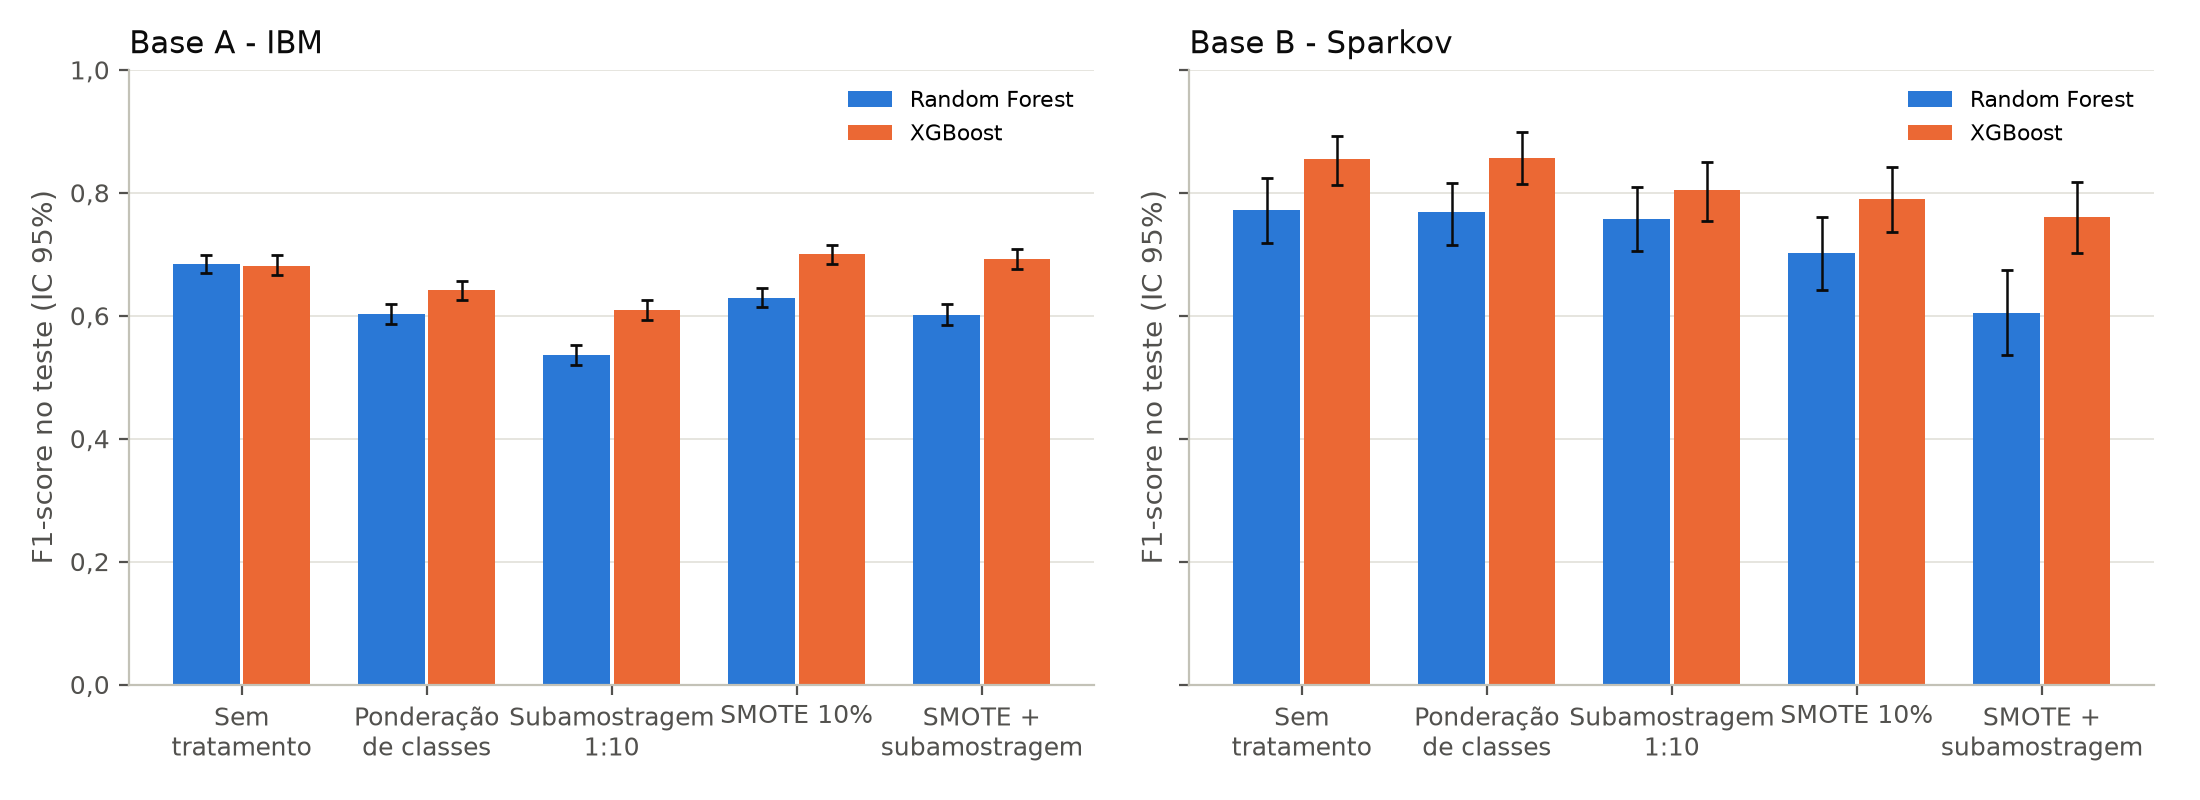

In [3]:
e2.figura()
display(Image(FIG / 'fig_exp2_balanceamento.png', width=1000))

**Leitura dos resultados.** Na Base B, ponderar ou não as classes dá o mesmo resultado; subamostragem e SMOTE pioram. Na Base A, os pesos integrais (≈1.500:1) prejudicam a generalização para 2019, e o XGBoost com SMOTE tem o melhor F1, por ganho de **precisão**, não de recall.

## 4.2 Otimização de hiperparâmetros (Experimento 3)
O Optuna (amostrador TPE) maximiza a AUPRC na validação. O modelo final de cada base é o de maior AUPRC na validação; o teste é consultado depois.

In [4]:
import exp3_otimizacao as e3
cols = ['modelo', 'tentativas', 'tempo_busca_s', 'val_pr_auc', 'f1', 'f1_padrao', 'dif_f1_vs_padrao', 'dif_f1_ic_inf', 'dif_f1_ic_sup', 'pr_auc', 'pr_auc_padrao', 'final']
display(e3.executar('B')[cols])
e3.executar('A')[cols]

,modelo,tentativas,tempo_busca_s,val_pr_auc,f1,f1_padrao,dif_f1_vs_padrao,dif_f1_ic_inf,dif_f1_ic_sup,pr_auc,pr_auc_padrao,final
0,XGBoost,60,441.200,0.946,0.856,0.856,-0.001,-0.029,0.028,0.902,0.907,False
1,LightGBM,60,418.200,0.950,0.850,0.851,-0.001,-0.027,0.026,0.912,0.893,True
2,MLP,40,216.100,0.914,0.772,0.718,0.054,0.012,0.097,0.838,0.784,False


,modelo,tentativas,tempo_busca_s,val_pr_auc,f1,f1_padrao,dif_f1_vs_padrao,dif_f1_ic_inf,dif_f1_ic_sup,pr_auc,pr_auc_padrao,final
0,XGBoost,14,1217.300,0.719,0.684,0.642,0.042,0.030,0.053,0.750,0.721,False
1,LightGBM,18,1259.600,0.728,0.691,0.296,0.395,0.381,0.411,0.759,0.189,True
2,MLP,13,1380.900,0.671,0.704,0.658,0.047,0.036,0.059,0.780,0.743,False


In [5]:
for chave in ('A', 'B'):
    m, meta = e3.carregar_final(chave)
    print(meta['nome_base'], '->', meta['familia'], '| limiar', round(meta['limiar'], 3), '| hiperparâmetros:', meta['params'])

Base A - IBM -> LightGBM | limiar 0.427 | hiperparâmetros: {'num_leaves': 88, 'learning_rate': 0.01502050588721324, 'min_child_samples': 823, 'min_child_weight': 7.470999264396441, 'subsample': 0.6849361159511912, 'colsample_bytree': 0.37180335718198315, 'reg_lambda': 0.16361835153720167, 'reg_alpha': 0.0063908159790543526, 'expoente_peso': 0.494561283928883}
Base B - Sparkov -> LightGBM | limiar 0.34 | hiperparâmetros: {'num_leaves': 45, 'learning_rate': 0.01787864467885192, 'min_child_samples': 96, 'min_child_weight': 0.00545012317177608, 'subsample': 0.876643165773264, 'colsample_bytree': 0.9389385121419516, 'reg_lambda': 0.8886691948953578, 'reg_alpha': 0.2674424156860115, 'expoente_peso': 0.2908612550759879}


**Leitura dos resultados.** A otimização favoreceu modelos regularizados e pesos de classe moderados na Base A, com ganhos significativos. Na Base B, o ganho foi pequeno. O modelo final das duas bases é o LightGBM otimizado, escolhido pela AUPRC na validação. Na Base A, a MLP foi um pouco melhor no teste, mas a escolha pelo teste tornaria a avaliação otimista.